# Are SHAP Feature Rankings Robust to Train–Test Split Ratios? A Repeated-Split Study Using Random Forest on Two Clinical Datasets
### Experiment 1 — Pima Indians Diabetes Dataset (Random Forest)

**Research questions:** Does the train–test split ratio affect (a) Random Forest
predictive performance and (b) the stability of SHAP-based feature-importance
rankings? And is the split ratio that gives the best predictive performance also the
one that gives the most stable explanations (the "performance–stability gap")?

This notebook is **Experiment 1** of a two-dataset study. Experiment 2 (UCI Combined
Heart Disease dataset) uses the same protocol. Neither experiment uses SMOTE: class
imbalance is handled with Random Forest class weighting (`class_weight="balanced"`) in
both. The one deliberate preprocessing difference is imputation: this experiment uses
MICE-style multivariate imputation because Pima has heavy, structured missingness
(Insulin ~48.7%, SkinThickness ~29.6%), whereas Experiment 2 has far less missingness
and keeps median imputation.

## Study design

A controlled comparative experiment. **Random Forest is the sole algorithm** used
throughout, so that any differences observed across conditions can be attributed to
the split ratio rather than to switching between algorithms.

**Five stratified split ratios:** 50:50, 60:40, 70:30, 80:20, 90:10.

**Each ratio is run 20 times** with different (but matched) random seeds — a single
split per ratio cannot distinguish "the ratio changed the result" from "this
particular random partition happened to change the result." Seeds are shared across
ratios (seed *k* produces the k-th split under every ratio), which allows a
**Friedman test** (a matched, non-parametric alternative to repeated-measures ANOVA)
to test whether split ratio has a systematic effect on performance, with **Nemenyi**
post-hoc pairwise comparisons if the Friedman test is significant.

**Design choice — retuning per repeat:** `RandomizedSearchCV` is re-run independently
for every (seed, ratio) combination, i.e. hyperparameters are re-optimized on each of
the 100 training partitions rather than tuned once and reused. This mirrors a real
deployment workflow (data changes → you retune) and means the reported variability
across repeats reflects **both** sampling variability and search stochasticity — which
is the more honest (if noisier) estimate of what practitioners would actually
experience. If you'd rather isolate pure sampling variability, tune once on a
reference split and reuse those hyperparameters everywhere — see the description
in Section 7.

**Compute budget:** 5 ratios × 20 repeats × (`RandomizedSearchCV`: `N_ITER` × `CV_FOLDS`
fits) is substantial. `N_REPEATS`, `N_ITER`, and `CV_FOLDS` are all set as constants in
Section 7 — turn them down for a quick test run, turn them up for the final results
you'll report.

## Pipeline overview

1. Load & inspect data
2. Clean (biologically-impossible zeros → NaN)
3. Outlier detection (IQR report) — outliers are **capped, never dropped** (see Section 5)
4. Leakage-safe pipeline: impute (MICE / `IterativeImputer`) → cap outliers (IQR) → scale →
   Random Forest (`class_weight="balanced"`), all fit on training folds/partitions only
5. For every (seed, ratio) pair: tune (`RandomizedSearchCV`, PR-AUC scoring) → evaluate
   on held-out test → compute SHAP (`TreeExplainer`) → store performance + feature ranking
6. Aggregate performance across repeats per ratio (mean ± 95% CI); Friedman + Nemenyi
   for formal comparison across ratios
7. Aggregate SHAP rankings across repeats per ratio; pairwise **stability** across all
   10 ratio-pairs using Kendall's τ, Spearman's ρ, Jaccard (Top-3 and Top-5), and mean
   absolute rank difference
8. Performance–stability gap check: does the best-performing ratio also produce the
   most stable explanations?


## 1. Imports

In [1]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import kendalltau, spearmanr, friedmanchisquare, loguniform, randint

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (exposes IterativeImputer)
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.exceptions import ConvergenceWarning
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
)




import shap

# Post-hoc Nemenyi test (pip install scikit-posthocs if not already installed)
import scikit_posthocs as sp

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_style("whitegrid")
warnings.filterwarnings("ignore", category=ConvergenceWarning)


## 2. Load Data

Pima Indians Diabetes Dataset: 768 observations, 8 clinical predictors, binary
outcome (500 non-diabetic / 268 diabetic, 65.1% / 34.9%). Loaded from a local CSV
bundled alongside this notebook.


In [2]:

DATA_PATH = "diabetes.csv"
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()


Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 3. Inspection

In [3]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:

df.describe().T


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64


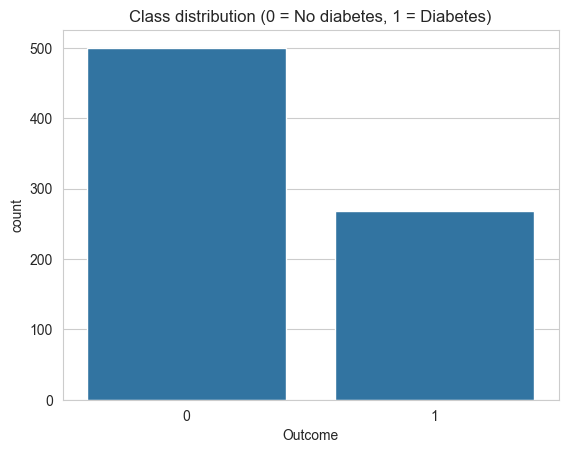

In [5]:

print(df["Outcome"].value_counts())
print(df["Outcome"].value_counts(normalize=True).round(4))

sns.countplot(x="Outcome", data=df)
plt.title("Class distribution (0 = No diabetes, 1 = Diabetes)")
plt.show()


In [6]:
# Zero values are physiologically implausible for these five columns and are used
# in this dataset as a missing-data placeholder.
zero_as_missing_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

zero_counts = (df[zero_as_missing_cols] == 0).sum()
zero_pct = (100 * zero_counts / len(df)).round(1)

print("Zero-value counts / percentage (treated as missing) per column:")
print(pd.DataFrame({"n_zero": zero_counts, "pct_zero": zero_pct}))

Zero-value counts / percentage (treated as missing) per column:
               n_zero  pct_zero
Glucose             5       0.7
BloodPressure      35       4.6
SkinThickness     227      29.6
Insulin           374      48.7
BMI                11       1.4


## 4. Cleaning

Zeros in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI` are converted
to `NaN`. Imputation itself happens **inside** the modelling pipeline (MICE, fit on
training data only per repeat) — not here — to avoid leaking test-partition
information into training.

**Missingness and imputation choice.** Missingness is substantial and uneven across
columns — `SkinThickness` (~29.6%) and especially `Insulin` (~48.7%) have close to, or
over, a third of values missing. Because these values are not missing at random in any
simple sense (they are strongly related to Glucose, BMI and other measured variables),
a single-column statistic such as the median would flatten that structure. **MICE-style
multivariate imputation** (`sklearn.impute.IterativeImputer` with `BayesianRidge`) is
therefore used: each incomplete feature is modelled from the others in a round-robin
fashion. KNN imputation was considered and rejected because, with up to ~49% of a
column missing, neighbour distances are computed on very few shared features and become
unreliable.

The imputer sits **inside** the modelling pipeline, so it is fit on training data only
(per repeat and per CV fold) and then applied to the test partition. Imputed values are
floored at 0 (`min_value=0`) since all five columns are strictly positive. The remaining
limitations are discussed in Section 14.


In [7]:

df_clean = df.copy()
df_clean[zero_as_missing_cols] = df_clean[zero_as_missing_cols].replace(0, np.nan)

print("Missing values after conversion:")
print(df_clean.isna().sum())
print("\nDuplicate rows:", df_clean.duplicated().sum())


Missing values after conversion:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Duplicate rows: 0


In [8]:

FEATURES = [c for c in df_clean.columns if c != "Outcome"]
TARGET = "Outcome"

# No categorical columns in this dataset; OneHotEncoder is retained in the
# ColumnTransformer purely for pipeline generality/reusability.
numeric_features = FEATURES
categorical_features = []

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Categorical features: []


## 5. Outlier Detection

With 768 rows total (and as few as ~77 in the smallest test partition), **rows are
never dropped for being outliers** — every row lost is signal that cannot be
recovered, and dropping tends to disproportionately remove extreme, sometimes
clinically meaningful, cases rather than noise.

Instead, outliers are **capped (winsorized)**, fit on training data only inside the
pipeline (Section 6), so every partition retains its full intended sample size.


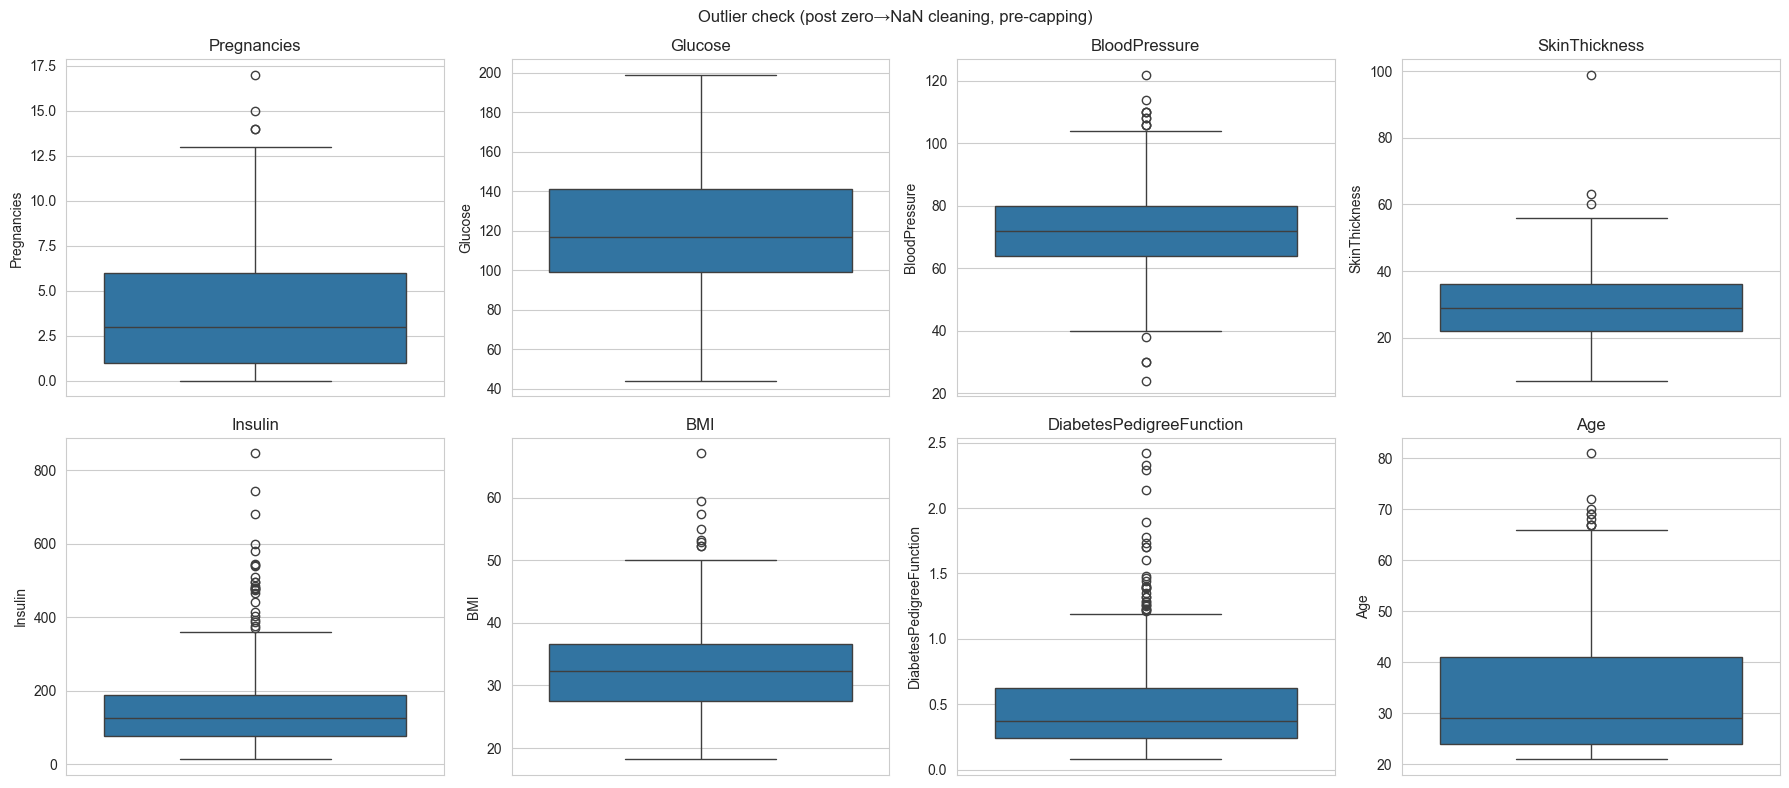

In [9]:

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), numeric_features):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Outlier check (post zero→NaN cleaning, pre-capping)")
plt.tight_layout()
plt.show()


In [10]:

def iqr_outlier_report(data, cols, k=1.5):
    rows = []
    for col in cols:
        q1, q3 = data[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - k * iqr, q3 + k * iqr
        n_outliers = ((data[col] < lower) | (data[col] > upper)).sum()
        rows.append({
            "Feature": col, "Q1": q1, "Q3": q3, "IQR": iqr,
            "Lower_bound": lower, "Upper_bound": upper,
            "N_outliers": n_outliers,
            "Pct_outliers": round(100 * n_outliers / len(data), 2),
        })
    return pd.DataFrame(rows).set_index("Feature")

outlier_report = iqr_outlier_report(df_clean, numeric_features)
display(outlier_report.style.format({
    "Q1": "{:.2f}", "Q3": "{:.2f}", "IQR": "{:.2f}",
    "Lower_bound": "{:.2f}", "Upper_bound": "{:.2f}", "Pct_outliers": "{:.2f}%",
}))


,Q1,Q3,IQR,Lower_bound,Upper_bound,N_outliers,Pct_outliers
Feature,,,,,,,
Pregnancies,1.00,6.00,5.00,-6.50,13.50,4,0.52%
Glucose,99.00,141.00,42.00,36.00,204.00,0,0.00%
BloodPressure,64.00,80.00,16.00,40.00,104.00,14,1.82%
SkinThickness,22.00,36.00,14.00,1.00,57.00,3,0.39%
Insulin,76.25,190.00,113.75,-94.38,360.62,24,3.12%
BMI,27.50,36.60,9.10,13.85,50.25,8,1.04%
DiabetesPedigreeFunction,0.24,0.63,0.38,-0.33,1.20,29,3.78%
Age,24.00,41.00,17.00,-1.50,66.50,9,1.17%


## 6. Leakage-Safe Preprocessing Pipeline

`ColumnTransformer` numeric branch: **MICE imputation** (`IterativeImputer`,
`BayesianRidge` estimator, `max_iter=10`, `min_value=0`) → **IQR-cap (winsorize)** →
`StandardScaler`. The `IQRCapper` is a small custom `scikit-learn`-compatible
transformer: it **learns** `Q1`/`Q3`/IQR bounds via `.fit()` on training data only,
then **clips** (never drops) values via `.transform()` — applied identically to train
and test, but bounds are learned from training data only. Capping runs after imputation,
so imputed values are also bounded.

**No SMOTE.** Class imbalance (65.1% / 34.9%) is handled with
`RandomForestClassifier(class_weight="balanced")`, which reweights samples inversely to
class frequency. This needs no resampling, creates no synthetic observations, and
leaves the training partition unchanged. The model pipeline is a standard
`sklearn.pipeline.Pipeline`, and because the whole pipeline is passed to
`RandomizedSearchCV`, imputation, capping and scaling are fit **only within training
folds/partitions** during both hyperparameter search and final fitting.


In [11]:

class IQRCapper(BaseEstimator, TransformerMixin):
    """Winsorizes each column to [Q1 - k*IQR, Q3 + k*IQR], fit on training data only.
    Never drops rows — only clips extreme values, so sample size is always preserved."""

    def __init__(self, k=1.5):
        self.k = k

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lower_, self.upper_ = {}, {}
        for col in X.columns:
            q1, q3 = X[col].quantile([0.25, 0.75])
            iqr = q3 - q1
            self.lower_[col] = q1 - self.k * iqr
            self.upper_[col] = q3 + self.k * iqr
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        for col in X.columns:
            X[col] = X[col].clip(lower=self.lower_[col], upper=self.upper_[col])
        return X.values

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features)



In [12]:
def make_preprocessor(cap_outliers=True, cap_k=1.5):
    # MICE-style imputation: each incomplete column is regressed on the others (chained
    # equations). Fit on training data only because it lives inside the pipeline.
    numeric_steps = [("imputer", IterativeImputer(
        estimator=BayesianRidge(), max_iter=10, min_value=0,
        random_state=RANDOM_STATE))]
    if cap_outliers:
        numeric_steps.append(("capper", IQRCapper(k=cap_k)))
    numeric_steps.append(("scaler", StandardScaler()))
    numeric_pipe = Pipeline(steps=numeric_steps)

    categorical_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer(transformers=[
        ("num", numeric_pipe, numeric_features),
        ("cat", categorical_pipe, categorical_features),
    ])


In [13]:
def make_pipeline(cap_outliers=True, cap_k=1.5):
    # No SMOTE: class imbalance is handled by class weighting inside the Random Forest.
    return Pipeline(steps=[
        ("preprocessor", make_preprocessor(cap_outliers=cap_outliers, cap_k=cap_k)),
        ("model", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
    ])


## 7. Random Forest Hyperparameter Search Space

`RandomizedSearchCV` with `N_ITER` sampled configurations and `CV_FOLDS`-fold
stratified cross-validation, scored on PR-AUC (`average_precision`) — the more
informative metric under class imbalance.

**To instead tune once and reuse fixed hyperparameters across all repeats** (isolating
pure sampling variability from search stochasticity), fit `RandomizedSearchCV` a
single time on a reference split, extract `best_params_`, and pass a plain
`RandomForestClassifier(**best_params_)` into the loop in Section 8 instead of
re-running the search each iteration.


In [14]:

PARAM_DIST = {
    "model__n_estimators": randint(100, 500),
    "model__max_depth": randint(3, 20),
    "model__min_samples_split": randint(2, 20),
    "model__min_samples_leaf": randint(1, 10),
    "model__max_features": ["sqrt", "log2", None],
}

N_ITER = 25          # per methodology: 25 sampled configurations
CV_FOLDS = 5          # per methodology: stratified 5-fold CV
N_REPEATS = 20         # matched repeats per split ratio (turn down for a quick test run)
SEEDS = list(range(N_REPEATS))


## 8. Experimental Protocol — 5 Ratios × 20 Matched Repeats

For every seed *k* (0–19) and every split ratio, the same seed drives the stratified
split — so run *k* under 50:50 and run *k* under 90:10 are "matched" for the Friedman
test in Section 10. For each of the 100 (seed, ratio) combinations:

1. Stratified split using seed *k*
2. `RandomizedSearchCV` tunes Random Forest on the training partition
3. Best estimator evaluated once on the held-out test partition (Accuracy, Precision,
   Recall, F1, ROC-AUC, PR-AUC)
4. SHAP (`TreeExplainer`) computed on the test partition; mean |SHAP| per feature →
   feature ranking, stored for the consistency analysis in Sections 11–13

**This cell is the expensive one.** With `N_ITER=25`, `CV_FOLDS=5`, `N_REPEATS=20`,
this is 5 × 20 × 25 × 5 = 12,500 Random Forest fits for tuning alone, plus 100 final
refits and 100 SHAP computations. Reduce `N_REPEATS`/`N_ITER`/`CV_FOLDS` in Section 7
for a fast smoke test before committing to a full run.


In [15]:
SPLIT_RATIOS = {
    "50:50": 0.50,
    "60:40": 0.40,
    "70:30": 0.30,
    "80:20": 0.20,
    "90:10": 0.10,
}

X = df_clean[FEATURES]
y = df_clean[TARGET]


def evaluate(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, y_proba),
        "PR_AUC": average_precision_score(y_true, y_proba),
    }

In [16]:
def get_shap_ranking(pipe, X_train, X_test):
    """Fits SHAP TreeExplainer on the tuned RF and returns mean|SHAP| per feature."""
    pre = pipe.named_steps["preprocessor"]
    model = pipe.named_steps["model"]

    X_test_t = pre.transform(X_test)
    feat_names = pre.get_feature_names_out()
    X_test_t = pd.DataFrame(X_test_t, columns=feat_names)

    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_test_t)

    if isinstance(shap_values, list):          # older shap API: list per class
        shap_values = shap_values[1]
    elif np.asarray(shap_values).ndim == 3:    # newer shap API: (n, f, n_classes)
        shap_values = np.asarray(shap_values)[:, :, 1]

    mean_abs_shap = np.abs(shap_values).mean(axis=0)

    return pd.Series(mean_abs_shap, index=feat_names)


# Common grids for averaging curves across repeats (raw curves have different
# numbers of thresholds per run, so they must be interpolated onto a shared
# x-axis before they can be meaningfully averaged).
ROC_GRID = np.linspace(0, 1, 100)   # common FPR grid
PR_GRID = np.linspace(0, 1, 100)    # common Recall grid

performance_records = []        # one row per (seed, ratio)
shap_importance_records = []   # one row per (seed, ratio), columns = features
roc_curve_records = []          # {"Split":..., "Seed":..., "tpr": array on ROC_GRID}
pr_curve_records = []           # {"Split":..., "Seed":..., "precision": array on PR_GRID}


for seed in SEEDS:
    for split_label, test_size in SPLIT_RATIOS.items():
        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=test_size,
            stratify=y,
            random_state=seed,
        )

        cv = StratifiedKFold(
            n_splits=CV_FOLDS,
            shuffle=True,
            random_state=seed,
        )

        search = RandomizedSearchCV(
            make_pipeline(),
            param_distributions=PARAM_DIST,
            n_iter=N_ITER,
            scoring="average_precision",
            cv=cv,
            random_state=seed,
            n_jobs=-1,
            refit=True,
        )

        search.fit(X_train, y_train)
        best_est = search.best_estimator_

        y_pred = best_est.predict(X_test)
        y_proba = best_est.predict_proba(X_test)[:, 1]

        metrics = evaluate(y_test, y_pred, y_proba)
        metrics.update({
            "Seed": seed,
            "Split": split_label,
            "Best_CV_PR_AUC": search.best_score_,
        })
        performance_records.append(metrics)

        # ROC curve, interpolated onto the common FPR grid
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        tpr_interp = np.interp(ROC_GRID, fpr, tpr)
        tpr_interp[0] = 0.0

        roc_curve_records.append({
            "Split": split_label,
            "Seed": seed,
            "tpr": tpr_interp,
        })

        # PR curve, interpolated onto the common Recall grid (recall must be
        # sorted ascending for np.interp, so reverse the sklearn output)
        prec, rec, _ = precision_recall_curve(y_test, y_proba)
        prec_interp = np.interp(PR_GRID, rec[::-1], prec[::-1])

        pr_curve_records.append({
            "Split": split_label,
            "Seed": seed,
            "precision": prec_interp,
        })

        importance = get_shap_ranking(best_est, X_train, X_test)
        importance["Seed"] = seed
        importance["Split"] = split_label
        shap_importance_records.append(importance)

    print(f"Seed {seed} complete across all 5 ratios.")


performance_df = pd.DataFrame(performance_records)
shap_importance_df = pd.DataFrame(shap_importance_records)

print("\nperformance_df shape:", performance_df.shape)
print("shap_importance_df shape:", shap_importance_df.shape)

Seed 0 complete across all 5 ratios.
Seed 1 complete across all 5 ratios.
Seed 2 complete across all 5 ratios.
Seed 3 complete across all 5 ratios.
Seed 4 complete across all 5 ratios.
Seed 5 complete across all 5 ratios.
Seed 6 complete across all 5 ratios.
Seed 7 complete across all 5 ratios.
Seed 8 complete across all 5 ratios.
Seed 9 complete across all 5 ratios.
Seed 10 complete across all 5 ratios.
Seed 11 complete across all 5 ratios.
Seed 12 complete across all 5 ratios.
Seed 13 complete across all 5 ratios.
Seed 14 complete across all 5 ratios.
Seed 15 complete across all 5 ratios.
Seed 16 complete across all 5 ratios.
Seed 17 complete across all 5 ratios.
Seed 18 complete across all 5 ratios.
Seed 19 complete across all 5 ratios.

performance_df shape: (100, 9)
shap_importance_df shape: (100, 10)


## 9. Performance — Aggregated Across Repeats, Per Ratio

One combined table (not six separate ones): mean ± 95% CI for every metric, per split
ratio.


In [17]:

def summarize_metric(df, metric, group_col="Split"):
    g = df.groupby(group_col)[metric]
    summary = g.agg(["mean", "std", "count"])
    summary["ci95"] = 1.96 * summary["std"] / np.sqrt(summary["count"])
    return summary.loc[list(SPLIT_RATIOS.keys())]

METRICS = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]
METRIC_LABELS = {
    "Accuracy": "Accuracy", "Precision": "Precision", "Recall": "Recall",
    "F1": "F1", "ROC_AUC": "ROC-AUC", "PR_AUC": "PR-AUC",
}

# Build one combined table: rows = split ratios, columns = metrics,
# each cell formatted as "mean ± 95% CI" to three decimal places.
combined_rows = {}
for split_label in SPLIT_RATIOS:
    row = {}
    for metric in METRICS:
        summary = summarize_metric(performance_df, metric)
        mean_val = summary.loc[split_label, "mean"]
        ci_val = summary.loc[split_label, "ci95"]
        row[METRIC_LABELS[metric]] = f"{mean_val:.3f} \u00b1 {ci_val:.3f}"
    combined_rows[split_label] = row

combined_table = pd.DataFrame(combined_rows).T.loc[list(SPLIT_RATIOS.keys())]
combined_table.index.name = "Split"
display(combined_table)


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Split,,,,,,
50:50,0.760 ± 0.008,0.637 ± 0.014,0.736 ± 0.028,0.681 ± 0.011,0.834 ± 0.006,0.699 ± 0.013
60:40,0.763 ± 0.009,0.637 ± 0.014,0.751 ± 0.018,0.688 ± 0.011,0.837 ± 0.009,0.703 ± 0.018
70:30,0.762 ± 0.012,0.638 ± 0.018,0.754 ± 0.025,0.690 ± 0.014,0.840 ± 0.010,0.713 ± 0.016
80:20,0.760 ± 0.014,0.631 ± 0.018,0.769 ± 0.028,0.691 ± 0.017,0.839 ± 0.014,0.722 ± 0.020
90:10,0.766 ± 0.017,0.642 ± 0.026,0.774 ± 0.042,0.698 ± 0.023,0.842 ± 0.018,0.729 ± 0.031


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


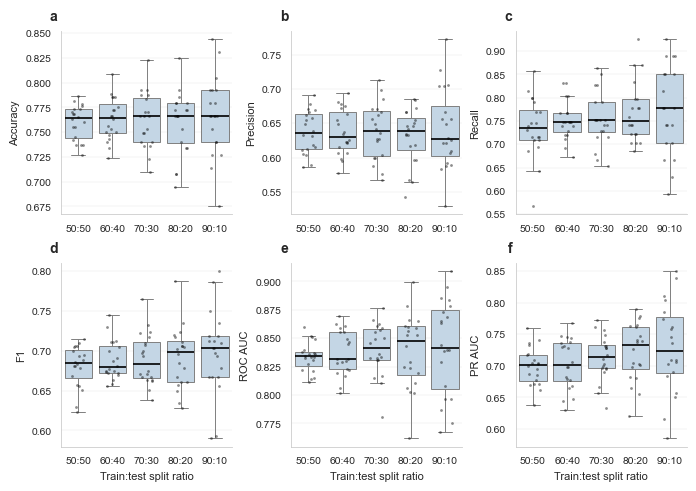

In [28]:
import io
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.size": 8, "axes.labelsize": 8,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
    "axes.linewidth": 0.6, "pdf.fonttype": 42, "ps.fonttype": 42,
})
W, DPI, NAME = 174 / 25.4, 600, "Fig1"
order = list(SPLIT_RATIOS.keys())

fig, axes = plt.subplots(2, 3, figsize=(W, 4.8), constrained_layout=True)
for i, (ax, metric) in enumerate(zip(axes.ravel(), METRICS)):
    sns.boxplot(data=performance_df, x="Split", y=metric, order=order, ax=ax,
                color="#BFD7EA", linewidth=0.7, fliersize=0,
                medianprops={"color": "black", "linewidth": 1.2})
    sns.stripplot(data=performance_df, x="Split", y=metric, order=order, ax=ax,
                  color="black", alpha=0.45, size=2, jitter=0.2)
    ax.set_ylabel(metric.replace("_", " "))
    ax.set_xlabel("Train:test split ratio" if i >= 3 else "")
    ax.text(-0.02, 1.04, "abcdef"[i], transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="bottom", ha="right")
    ax.grid(axis="y", linewidth=0.3, alpha=0.5)
    sns.despine(ax=ax)

fig.savefig(f"{NAME}.pdf")
fig.savefig(f"{NAME}.eps")
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=DPI, facecolor="white")
buf.seek(0)
Image.open(buf).convert("RGB").save(f"{NAME}.tiff", dpi=(DPI, DPI), compression="tiff_lzw")
plt.show()

## 9b. ROC and PR Curves — Mean Across Repeats, Per Ratio

Plotting all 100 raw curves individually would produce an unreadable overlapping mess
and a 100-entry legend. Instead, each split ratio's 20 repeat-curves are interpolated
onto a common grid and averaged, giving **one clean line per ratio** (5 lines total)
with a shaded ±1 SD band showing repeat-to-repeat variability. The legend carries the
mean AUC for each ratio directly, so the two panels are fully self-explanatory without
overlapping labels.


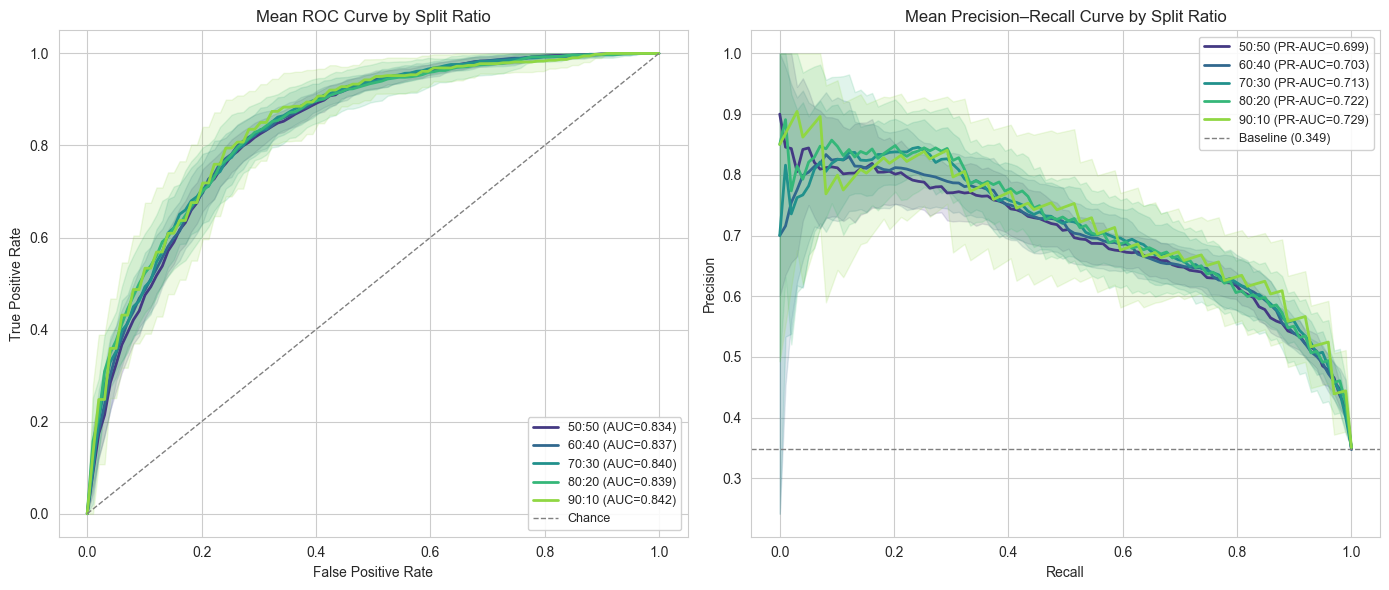

In [19]:

roc_df = pd.DataFrame(roc_curve_records)
pr_df = pd.DataFrame(pr_curve_records)

palette = dict(zip(SPLIT_RATIOS.keys(), sns.color_palette("viridis", n_colors=len(SPLIT_RATIOS))))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- ROC panel ---
ax = axes[0]
for split_label in SPLIT_RATIOS:
    tprs = np.vstack(roc_df.loc[roc_df["Split"] == split_label, "tpr"].values)
    mean_tpr = tprs.mean(axis=0)
    std_tpr = tprs.std(axis=0)
    mean_roc_auc = summarize_metric(performance_df, "ROC_AUC").loc[split_label, "mean"]

    color = palette[split_label]
    ax.plot(ROC_GRID, mean_tpr, color=color, lw=2,
            label=f"{split_label} (AUC={mean_roc_auc:.3f})")
    ax.fill_between(ROC_GRID, np.clip(mean_tpr - std_tpr, 0, 1),
                     np.clip(mean_tpr + std_tpr, 0, 1), color=color, alpha=0.15)

ax.plot([0, 1], [0, 1], linestyle="--", color="grey", lw=1, label="Chance")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Mean ROC Curve by Split Ratio")
ax.legend(loc="lower right", fontsize=9, framealpha=0.9)

# --- PR panel ---
ax = axes[1]
for split_label in SPLIT_RATIOS:
    precs = np.vstack(pr_df.loc[pr_df["Split"] == split_label, "precision"].values)
    mean_prec = precs.mean(axis=0)
    std_prec = precs.std(axis=0)
    mean_pr_auc = summarize_metric(performance_df, "PR_AUC").loc[split_label, "mean"]

    color = palette[split_label]
    ax.plot(PR_GRID, mean_prec, color=color, lw=2,
            label=f"{split_label} (PR-AUC={mean_pr_auc:.3f})")
    ax.fill_between(PR_GRID, np.clip(mean_prec - std_prec, 0, 1),
                     np.clip(mean_prec + std_prec, 0, 1), color=color, alpha=0.15)

baseline = df_clean[TARGET].mean()
ax.axhline(baseline, linestyle="--", color="grey", lw=1, label=f"Baseline ({baseline:.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Mean Precision–Recall Curve by Split Ratio")
ax.legend(loc="upper right", fontsize=9, framealpha=0.9)

plt.tight_layout()
plt.show()


## 10. Statistical Comparison of Split Ratios — Friedman + Nemenyi

The Friedman test is the matched, non-parametric analogue of repeated-measures ANOVA:
it tests whether the 5 split ratios differ systematically in **PR-AUC** (primary
metric), using the fact that each seed produces one matched observation per ratio. If
significant, Nemenyi post-hoc pairwise comparisons identify *which* ratios differ.


In [20]:

PRIMARY_METRIC = "PR_AUC"

wide = performance_df.pivot(index="Seed", columns="Split", values=PRIMARY_METRIC)[
    list(SPLIT_RATIOS.keys())
]
display(wide.style.format("{:.4f}"))

stat, p_value = friedmanchisquare(*[wide[col] for col in wide.columns])
print(f"\nFriedman test on {PRIMARY_METRIC}: statistic={stat:.4f}, p-value={p_value:.4g}")

if p_value < 0.05:
    print("→ Significant difference across split ratios (p < 0.05). Running Nemenyi post-hoc...")
    nemenyi = sp.posthoc_nemenyi_friedman(wide.values)
    nemenyi.index = wide.columns
    nemenyi.columns = wide.columns
    display(nemenyi.style.format("{:.4f}").background_gradient(cmap="RdYlGn_r", vmin=0, vmax=0.1))
    print("(Values are p-values for each pairwise comparison; < 0.05 = significantly different)")
else:
    print("→ No significant difference across split ratios (p ≥ 0.05): "
          f"{PRIMARY_METRIC} does not vary systematically with split ratio in this study.")


Split,50:50,60:40,70:30,80:20,90:10
Seed,,,,,
0,0.7170,0.6674,0.6949,0.7787,0.8496
1,0.6712,0.6475,0.6660,0.6831,0.5854
2,0.7030,0.7062,0.7030,0.7048,0.7459
3,0.7404,0.7444,0.6969,0.7034,0.8394
4,0.6626,0.6657,0.6578,0.6644,0.6156
5,0.7333,0.6979,0.7308,0.7019,0.7088
6,0.7043,0.7299,0.7482,0.7472,0.7619
7,0.6853,0.6829,0.7004,0.7612,0.7858
8,0.6782,0.6294,0.6341,0.6207,0.6837



Friedman test on PR_AUC: statistic=7.8400, p-value=0.09762
→ No significant difference across split ratios (p ≥ 0.05): PR_AUC does not vary systematically with split ratio in this study.


## 11. SHAP Feature Rankings — Aggregated Across Repeats, Per Ratio

For each (seed, ratio), features are ranked by mean |SHAP| (1 = most important). This
produces a distribution of ranks per feature per ratio across the 20 repeats — reported
as the **mean rank**, with the underlying spread visualized to show how much rank
position itself fluctuates from repeat to repeat, before ever comparing across ratios.


In [21]:

feature_cols = [c for c in shap_importance_df.columns if c not in ("Seed", "Split")]

rank_records = []
for _, row in shap_importance_df.iterrows():
    ranks = row[feature_cols].rank(ascending=False)
    rec = {"Seed": row["Seed"], "Split": row["Split"]}
    rec.update(ranks.to_dict())
    rank_records.append(rec)

rank_long_df = pd.DataFrame(rank_records)

mean_rank_by_split = (
    rank_long_df.groupby("Split")[feature_cols].mean().loc[list(SPLIT_RATIOS.keys())].T
)
print("Mean SHAP-importance rank by feature and split (1 = most important, averaged over repeats):")
display(mean_rank_by_split.style.format("{:.2f}").background_gradient(cmap="YlGnBu_r", axis=1))


Mean SHAP-importance rank by feature and split (1 = most important, averaged over repeats):


Split,50:50,60:40,70:30,80:20,90:10
num__Pregnancies,6.50,6.30,6.45,6.40,6.65
num__Glucose,1.05,1.10,1.00,1.10,1.05
num__BloodPressure,7.90,7.95,8.00,8.00,8.00
num__SkinThickness,5.40,5.95,5.35,6.00,5.75
num__Insulin,2.15,2.10,2.05,1.90,1.95
num__BMI,3.40,3.50,3.60,3.40,3.55
num__DiabetesPedigreeFunction,5.55,5.50,5.95,5.55,5.60
num__Age,4.05,3.60,3.60,3.65,3.45


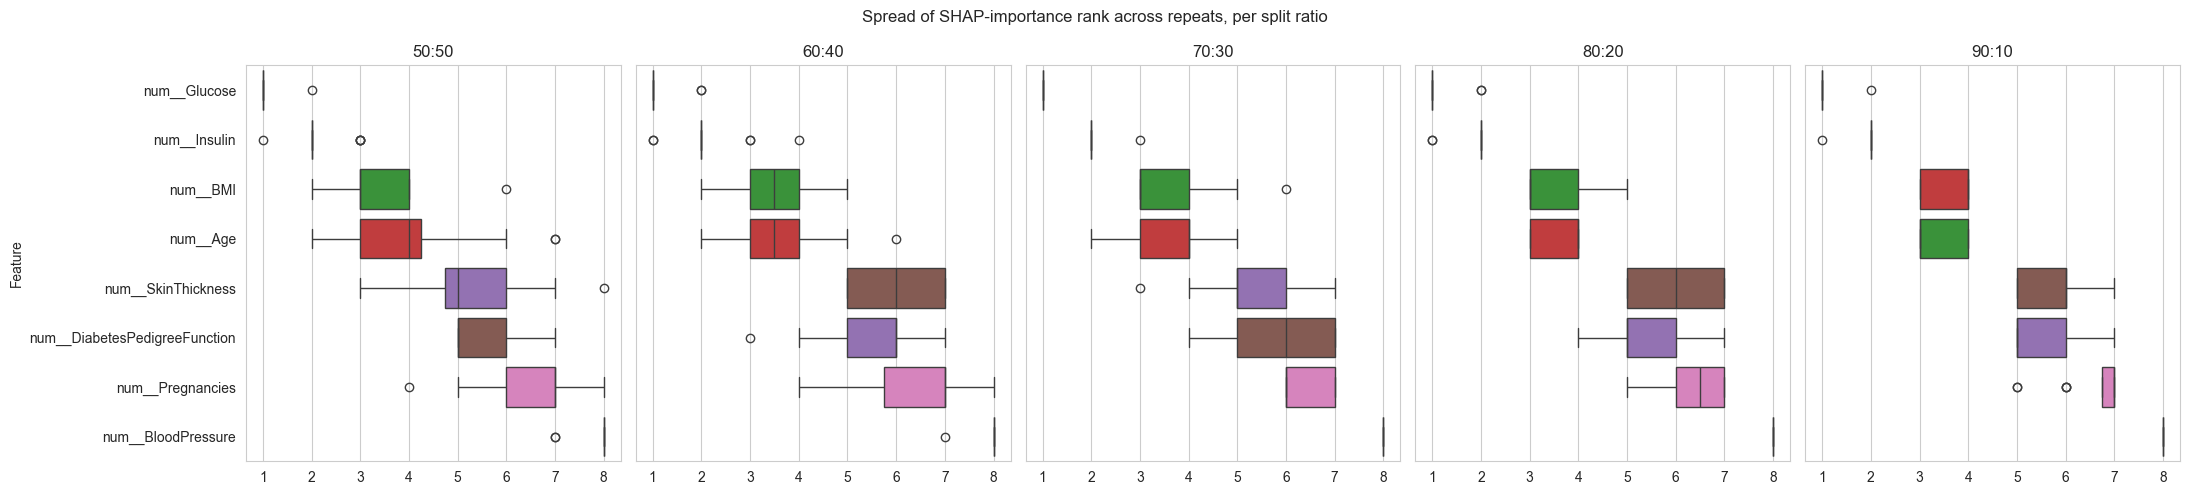

In [22]:

fig, axes = plt.subplots(1, len(SPLIT_RATIOS), figsize=(22, 5), sharey=True)
for ax, split_label in zip(axes, SPLIT_RATIOS):
    sub = rank_long_df[rank_long_df["Split"] == split_label][feature_cols]
    order = sub.mean().sort_values().index
    sns.boxplot(data=sub[order], orient="h", ax=ax)
    ax.set_title(split_label)
axes[0].set_ylabel("Feature")
plt.suptitle("Spread of SHAP-importance rank across repeats, per split ratio")
plt.tight_layout()
plt.show()


### 11.1 Mean |SHAP| Magnitude by Split — Side-by-Side Subplots

Rank tells you *ordering*; magnitude tells you *how much* a feature matters relative to
the others. Each panel below is one split ratio's mean |SHAP| value per feature
(averaged across the 20 repeats), as a horizontal bar chart, all sharing the same x-axis
scale for direct visual comparison across ratios. Horizontal bars avoid the rotated,
overlapping tick labels that vertical bars would produce with 8 feature names.


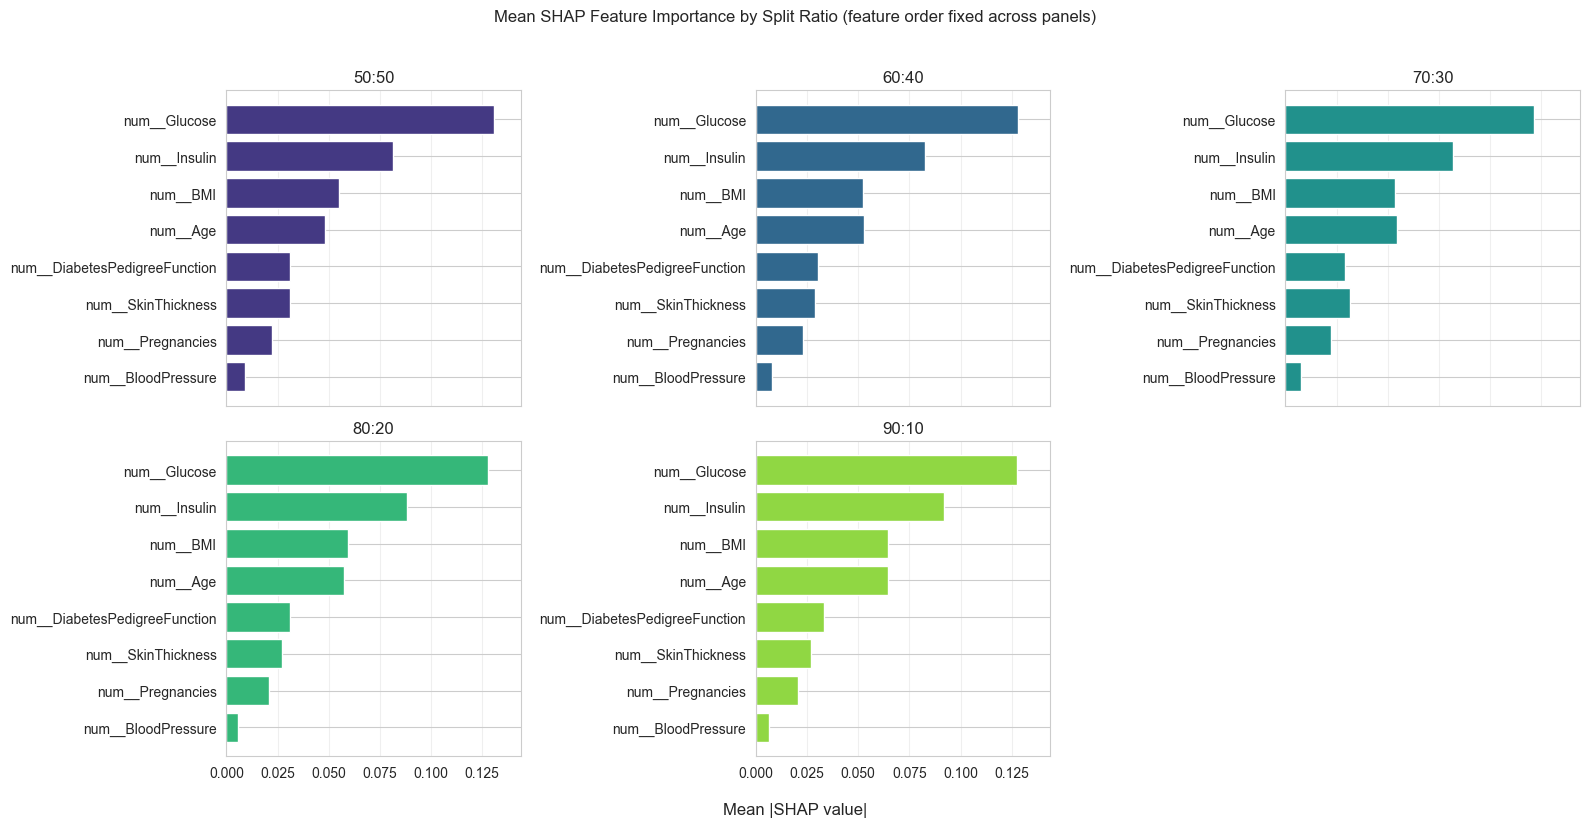

In [23]:

mean_magnitude_by_split = (
    shap_importance_df.groupby("Split")[feature_cols].mean().loc[list(SPLIT_RATIOS.keys())]
)
global_order = mean_magnitude_by_split.mean(axis=0).sort_values(ascending=True).index
x_max = mean_magnitude_by_split.values.max() * 1.1  # shared x-axis across all panels

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
axes = axes.ravel()

for ax, split_label in zip(axes, SPLIT_RATIOS):
    values = mean_magnitude_by_split.loc[split_label, global_order]
    colors = [palette[split_label]] * len(values)
    ax.barh(global_order, values, color=colors)
    ax.set_title(split_label)
    ax.set_xlim(0, x_max)
    ax.grid(axis="x", alpha=0.3)

# Hide the unused 6th subplot (5 ratios in a 2x3 grid)
axes[-1].axis("off")

fig.supxlabel("Mean |SHAP value|")
plt.suptitle("Mean SHAP Feature Importance by Split Ratio (feature order fixed across panels)", y=1.02)
plt.tight_layout()
plt.show()


## 12. Explanation Stability Across Split Ratios

Using the **mean rank per feature per ratio** (Section 11) as each ratio's summary
ranking, all 10 pairwise ratio comparisons are quantified with four complementary
measures:

- **Kendall's τ** — rank agreement between two rankings
- **Spearman's ρ** — correlation between rank positions
- **Jaccard similarity, Top-3 and Top-5** — set overlap of the most important features
  (Top-10 is not used: with only 8 predictors it would trivially always equal the full
  feature set and carry no discriminative value)
- **Mean absolute rank difference** — average shift in rank position per feature


In [24]:

def jaccard(set_a, set_b):
    set_a, set_b = set(set_a), set(set_b)
    return len(set_a & set_b) / len(set_a | set_b)

splits_list = list(SPLIT_RATIOS.keys())
pairs = [(a, b) for i, a in enumerate(splits_list) for b in splits_list[i + 1:]]

consistency_rows = []
for a, b in pairs:
    rank_a = mean_rank_by_split[a]
    rank_b = mean_rank_by_split[b]

    tau, _ = kendalltau(rank_a, rank_b)
    rho, _ = spearmanr(rank_a, rank_b)

    top3_a = rank_a.nsmallest(3).index
    top3_b = rank_b.nsmallest(3).index
    top5_a = rank_a.nsmallest(5).index
    top5_b = rank_b.nsmallest(5).index

    mean_abs_diff = (rank_a - rank_b).abs().mean()

    consistency_rows.append({
        "Split_A": a, "Split_B": b,
        "Kendall_tau": tau, "Spearman_rho": rho,
        "Jaccard_top3": jaccard(top3_a, top3_b),
        "Jaccard_top5": jaccard(top5_a, top5_b),
        "Mean_abs_rank_diff": mean_abs_diff,
    })

consistency_df = pd.DataFrame(consistency_rows)
display(consistency_df.style.format({
    "Kendall_tau": "{:.3f}", "Spearman_rho": "{:.3f}",
    "Jaccard_top3": "{:.3f}", "Jaccard_top5": "{:.3f}", "Mean_abs_rank_diff": "{:.3f}",
}))


,Split_A,Split_B,Kendall_tau,Spearman_rho,Jaccard_top3,Jaccard_top5,Mean_abs_rank_diff
0,50:50,60:40,0.929,0.976,1.000,0.667,0.187
1,50:50,70:30,0.982,0.994,1.000,1.000,0.175
2,50:50,80:20,0.929,0.976,1.000,0.667,0.187
3,50:50,90:10,0.857,0.952,0.500,0.667,0.200
4,60:40,70:30,0.909,0.970,1.000,0.667,0.188
5,60:40,80:20,1.000,1.000,1.000,1.000,0.075
6,60:40,90:10,0.929,0.976,0.500,1.000,0.138
7,70:30,80:20,0.909,0.970,1.000,0.667,0.200
8,70:30,90:10,0.909,0.970,0.500,0.667,0.163
9,80:20,90:10,0.929,0.976,0.500,1.000,0.125


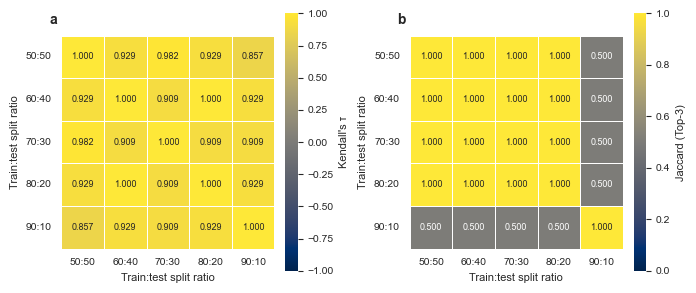

In [29]:
import io
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.size": 8, "axes.labelsize": 8,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
    "axes.linewidth": 0.6, "pdf.fonttype": 42, "ps.fonttype": 42,
})
W, DPI, NAME = 174 / 25.4, 600, "Fig2"

def to_square(df, value_col):
    sq = pd.DataFrame(index=splits_list, columns=splits_list, dtype=float)
    for _, row in df.iterrows():
        sq.loc[row["Split_A"], row["Split_B"]] = row[value_col]
        sq.loc[row["Split_B"], row["Split_A"]] = row[value_col]
    diag_val = 1.0 if value_col != "Mean_abs_rank_diff" else 0.0
    for s in splits_list:
        sq.loc[s, s] = diag_val
    return sq.astype(float)

fig, axes = plt.subplots(1, 2, figsize=(W, 3.3), constrained_layout=True)
panels = [("Kendall_tau", -1, 1, "Kendall's \u03c4"),
          ("Jaccard_top3", 0, 1, "Jaccard (Top-3)")]
for i, (ax, (col, vmin, vmax, lab)) in enumerate(zip(axes, panels)):
    sns.heatmap(to_square(consistency_df, col), annot=True, fmt=".3f",
                annot_kws={"size": 6.5}, cmap="cividis", vmin=vmin, vmax=vmax,
                linewidths=0.4, linecolor="white", square=True, ax=ax,
                cbar_kws={"shrink": 0.8, "label": lab})
    ax.set_xlabel("Train:test split ratio")
    ax.set_ylabel("Train:test split ratio")
    ax.tick_params(axis="y", rotation=0)
    ax.tick_params(axis="x", rotation=0)
    ax.text(-0.02, 1.04, "ab"[i], transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="bottom", ha="right")

fig.savefig(f"{NAME}.pdf")
fig.savefig(f"{NAME}.eps")
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=DPI, facecolor="white")
buf.seek(0)
Image.open(buf).convert("RGB").save(f"{NAME}.tiff", dpi=(DPI, DPI), compression="tiff_lzw")
plt.show()

In [26]:

print("Summary consistency statistics across all 10 ratio-pairs:")
display(consistency_df[["Kendall_tau", "Spearman_rho", "Jaccard_top3",
                          "Jaccard_top5", "Mean_abs_rank_diff"]].describe().loc[["mean", "std", "min", "max"]])


Summary consistency statistics across all 10 ratio-pairs:


,Kendall_tau,Spearman_rho,Jaccard_top3,Jaccard_top5,Mean_abs_rank_diff
mean,0.928113,0.976140,0.800000,0.800000,0.16375
std,0.039687,0.013183,0.258199,0.172133,0.04016
min,0.857143,0.952381,0.500000,0.666667,0.07500
max,1.000000,1.000000,1.000000,1.000000,0.20000


## 13. The Performance–Stability Gap: Does the Best-Performing Ratio Also Give the Most Stable Explanation?

Exploratory, not assumed: is the split ratio with the strongest mean PR-AUC also the
one whose feature ranking is most stable (highest mean τ against the other four)?
Mean τ values are compared at three decimal places, and any ties for the highest value
are reported as ties rather than broken arbitrarily.


In [27]:

best_ratio_by_perf = summarize_metric(performance_df, "PR_AUC")["mean"].idxmax()

mean_tau_per_split = {}
for s in splits_list:
    taus = [
        row["Kendall_tau"] for _, row in consistency_df.iterrows()
        if s in (row["Split_A"], row["Split_B"])
    ]
    mean_tau_per_split[s] = np.mean(taus)

# Ties are judged at the same 3-decimal precision that is reported
tau_rounded = {s: round(v, 3) for s, v in mean_tau_per_split.items()}
max_tau = max(tau_rounded.values())
most_stable_ratios = [s for s, v in tau_rounded.items() if v == max_tau]

print(f"Best-performing ratio (mean PR-AUC across {N_REPEATS} repeats): {best_ratio_by_perf}")
print(f"Most stable ratio(s) (highest mean Kendall's tau vs. the other 4): "
      f"{', '.join(most_stable_ratios)}  (tau = {max_tau:.3f})")
print("\nMean tau per ratio:")
for s, v in mean_tau_per_split.items():
    print(f"  {s}: {v:.3f}")

if best_ratio_by_perf in most_stable_ratios and len(most_stable_ratios) == 1:
    print("\n→ The best-performing ratio is ALSO the single most stable ratio for explanations.")
elif best_ratio_by_perf in most_stable_ratios:
    print("\n→ The best-performing ratio is TIED for the most stable explanations "
          f"(with {', '.join(r for r in most_stable_ratios if r != best_ratio_by_perf)}).")
else:
    print("\n→ Performance and explanation stability point to DIFFERENT ratios — "
          "the performance–stability gap. Worth discussing as a finding, not "
          "collapsing into a single 'best' recommendation.")


Best-performing ratio (mean PR-AUC across 20 repeats): 90:10
Most stable ratio(s) (highest mean Kendall's tau vs. the other 4): 60:40, 80:20  (tau = 0.942)

Mean tau per ratio:
  50:50: 0.924
  60:40: 0.942
  70:30: 0.927
  80:20: 0.942
  90:10: 0.906

→ Performance and explanation stability point to DIFFERENT ratios — the performance–stability gap. Worth discussing as a finding, not collapsing into a single 'best' recommendation.


## 14. Limitations

State explicitly in the write-up:

1. **Two datasets, one algorithm.** Findings describe Random Forest on the Pima Indians
   Diabetes Dataset (Experiment 1) and the UCI Combined Heart Disease dataset
   (Experiment 2) under this specific preprocessing pipeline — not a general claim
   about split-ratio effects across other datasets or algorithms.
2. **Missingness and imputation.** `Insulin` (~48.7%) and `SkinThickness` (~29.6%) had
   substantial missing data, addressed via training-only MICE-style imputation
   (`IterativeImputer` + `BayesianRidge`). This is a single imputation (no uncertainty
   propagation across multiple imputed datasets), and for these two features the SHAP
   attributions are partly driven by imputed rather than observed values. The influence
   of the imputation model on the SHAP explanations cannot be fully separated from the
   split-ratio effect being studied.
3. **Test-set size varies by ratio** (from ~77 observations at 90:10 to ~384 at
   50:50), which affects the precision of SHAP estimates independently of anything
   about the ratio itself "destabilizing" explanations. Repeating each ratio 20 times
   and reporting aggregated (mean-rank) statistics mitigates, but does not eliminate,
   this confound.
4. **Retuning per repeat** (Section 7/8) means reported variability reflects both
   sampling variability and hyperparameter-search stochasticity, not sampling
   variability alone.
5. **Preprocessing differs between experiments.** Experiment 1 uses MICE imputation
   (heavy missingness); Experiment 2 uses median imputation (little missingness). Both
   use Random Forest class weighting rather than resampling, but this means
   preprocessing is matched in philosophy, not identical, across the two datasets.
